## Design a kNN classifier from scratch!
1. Use the same problem as the previous question (i.e. forest-urban
classification)
2. Design a k-NN classifier now; write all steps clearly
3. Present the results
4. Change k to 1 to 3 to 5 and comment on the differences you
observe

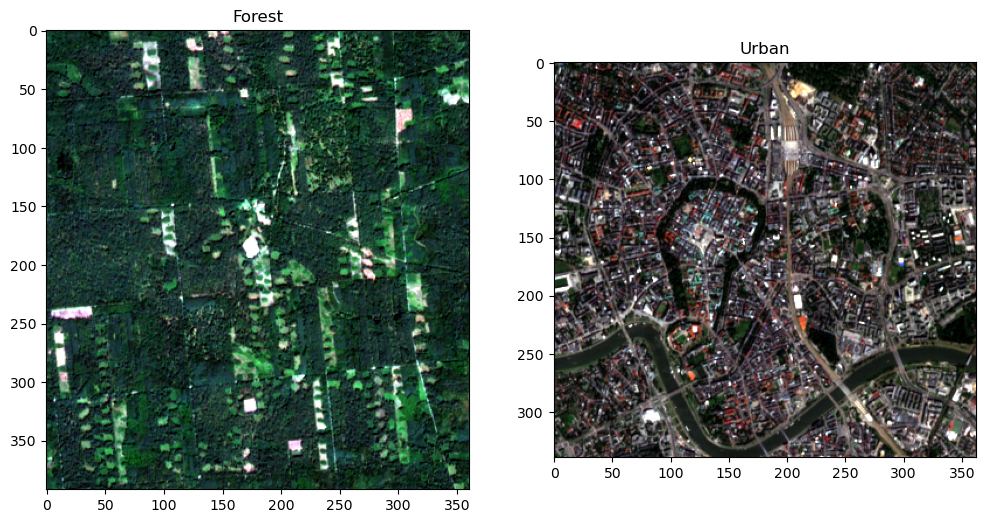

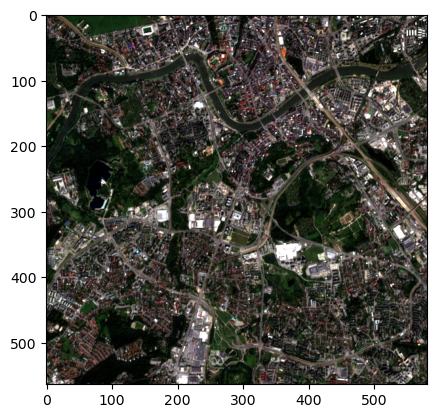

In [123]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio
from matplotlib.patches import Patch
from scipy import stats

DATA = Path("./scenes")

S2_BANDS = ["B02", "B03", "B04"]
S2_BANDS.reverse()

S2_BAND_NAMES = {
    "B02": "Blue",
    "B03": "Green",
    "B04": "Red",
}

S2_BAND_COLORS = {
    "B04": "red",
    "B03": "green",
    "B02": "blue",
}


def percentile_stretch(array: np.ndarray, lower_percentile: int = 1, upper_percentile: int = 99):
    p_low, p_high = np.percentile(array, (lower_percentile, upper_percentile))
    clipped = np.clip(array, p_low, p_high)
    return (clipped - p_low) / (p_high - p_low)


def get_raster_image(filename: str) -> np.ndarray:
    image_bands = []
    for band in S2_BANDS:
        with rasterio.open(DATA / f"{filename}_{band}.tif") as src:
            image_bands.append(src.read(1).astype(np.float32) / 10000.0)
    return np.dstack(image_bands)


def to_rgb(image: np.ndarray) -> np.ndarray:
    return np.dstack([percentile_stretch(image[:, :, i]) for i in range(image.shape[-1])])


def display_raster_image(first_image: np.ndarray, second_image: np.ndarray, first_title: str = "", second_title: str = ""):
    _, ax = plt.subplots(1, 2, figsize=(12, 12))
    ax[0].imshow(to_rgb(first_image))
    ax[1].imshow(to_rgb(second_image))
    ax[0].set_title(first_title)
    ax[1].set_title(second_title)
    plt.show()


def compare(image: np.ndarray, preds: np.ndarray, title: str = ""):
    legend = [
        Patch(facecolor="blue", label="Forest"),
        Patch(facecolor="red", label="Urban"),
    ]
    rgb = to_rgb(image)
    _, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(rgb)
    ax[0].set_title("RGB")

    ax[1].imshow(preds, cmap="bwr", vmin=0, vmax=1)
    ax[1].set_title("Prediction" + (f" ({title})" if title else ""))
    ax[1].legend(handles=legend, loc="upper right")

    ax[2].imshow(rgb)
    ax[2].imshow(preds, cmap="bwr", vmin=0, vmax=1, alpha=0.35)
    ax[2].set_title("Overlay")
    ax[2].legend(handles=legend, loc="upper right")

    for a in ax:
        a.axis("off")
    plt.tight_layout()
    plt.show()


s2_forest = get_raster_image("s2_forest")
s2_urban = get_raster_image("s2_urban")
s2_mixed = get_raster_image("s2_mixed")

display_raster_image(s2_forest, s2_urban, "Forest", "Urban")

plt.imshow(to_rgb(s2_mixed))

In [124]:
rng = np.random.default_rng(0)

X_forest = rng.choice(s2_forest.reshape(-1, s2_forest.shape[-1]), size=2000, replace=False)
X_urban = rng.choice(s2_urban.reshape(-1, s2_urban.shape[-1]), size=2000, replace=False)

# above we are essentially creating both model and dataset, model because in kNN we don't have "train phase" per se, the dataset is the model, we will assign the class basing on nearest samples to the analysed sample

X_train = np.vstack([X_forest, X_urban])
y_train = np.concatenate([
    np.zeros(len(X_forest), dtype=int),
    np.ones(len(X_urban), dtype=int),
])

print(X_train.shape, y_train.shape)

(4000, 3) (4000,)


In [125]:
# kNN classifier
def predict_single(pixel: np.ndarray, X_train: np.ndarray, Y_train: np.ndarray, k: int):
    dists = np.linalg.norm(X_train - pixel, axis=1) # subtract pixel from whole dataset, then calculate norm
    nn_idx = np.argpartition(dists, k)[:k] # take k nearest vectors
    nn_labels = Y_train[nn_idx] # get nearest vectors classes
    return int(np.bincount(nn_labels).argmax()) # count classes and return one that is more numerous

X_test = s2_mixed.reshape(-1, 3)
preds_1k = np.array([predict_single(p, X_train, y_train, 1) for p in X_test])
preds_3k = np.array([predict_single(p, X_train, y_train, 3) for p in X_test])
preds_5k = np.array([predict_single(p, X_train, y_train, 5) for p in X_test])

pred_1k_map = preds_1k.reshape(s2_mixed.shape[:2])
pred_3k_map = preds_3k.reshape(s2_mixed.shape[:2])
pred_5k_map = preds_5k.reshape(s2_mixed.shape[:2])

# above we are obtaining the prediction maps for each k hyperparameter value

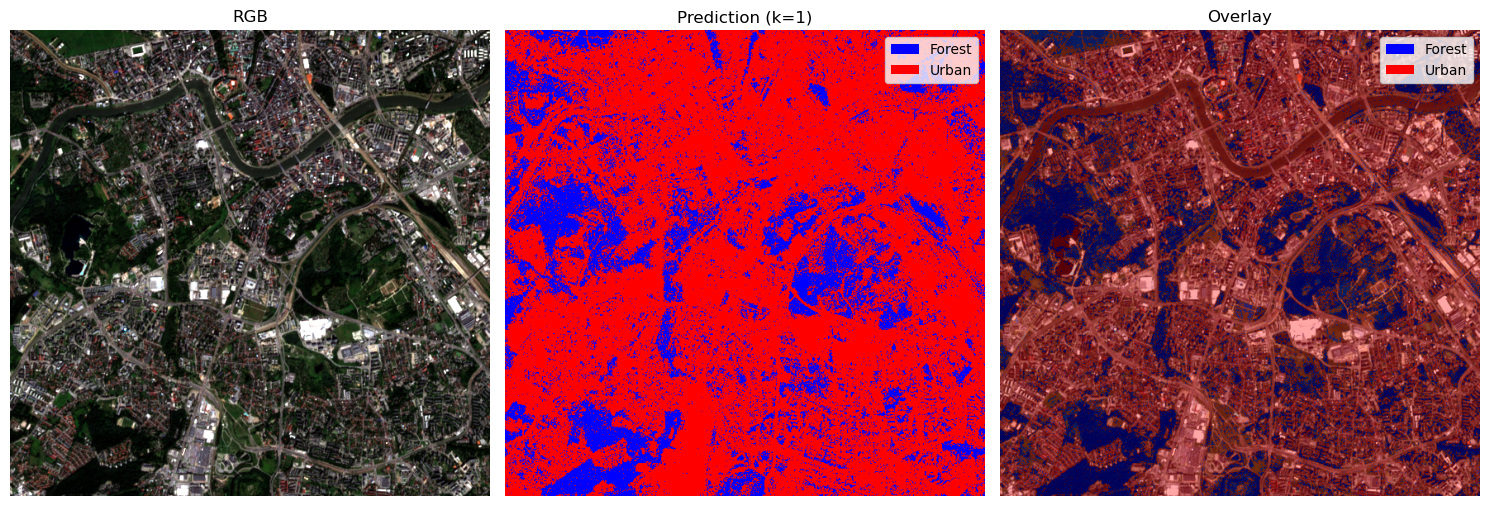

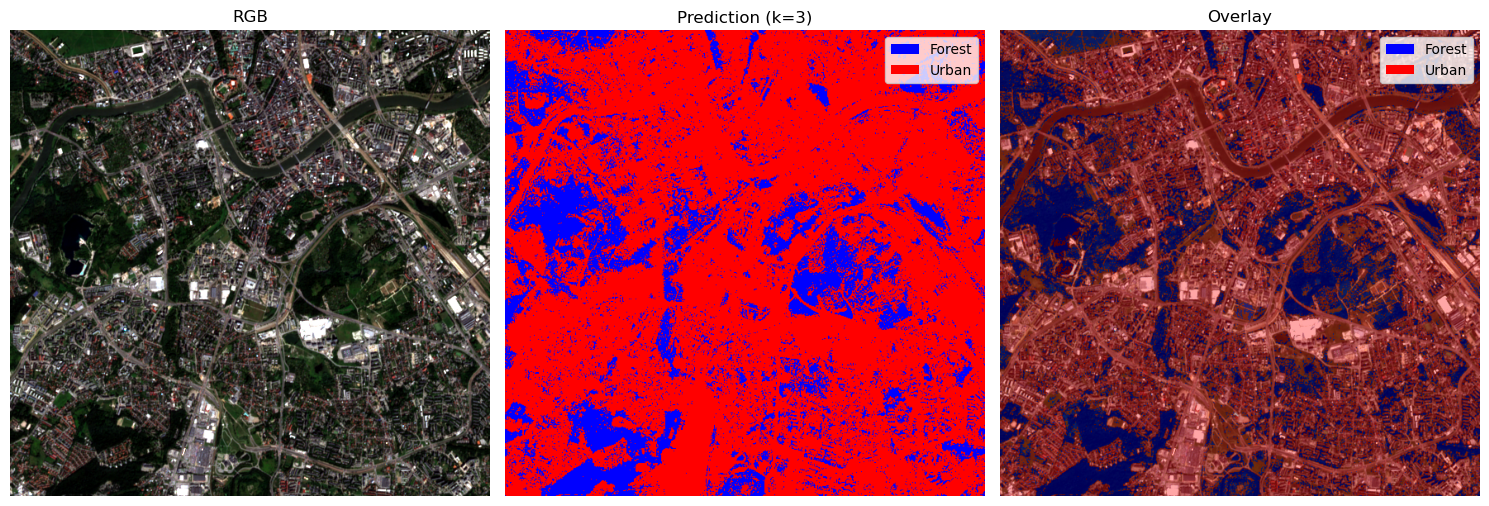

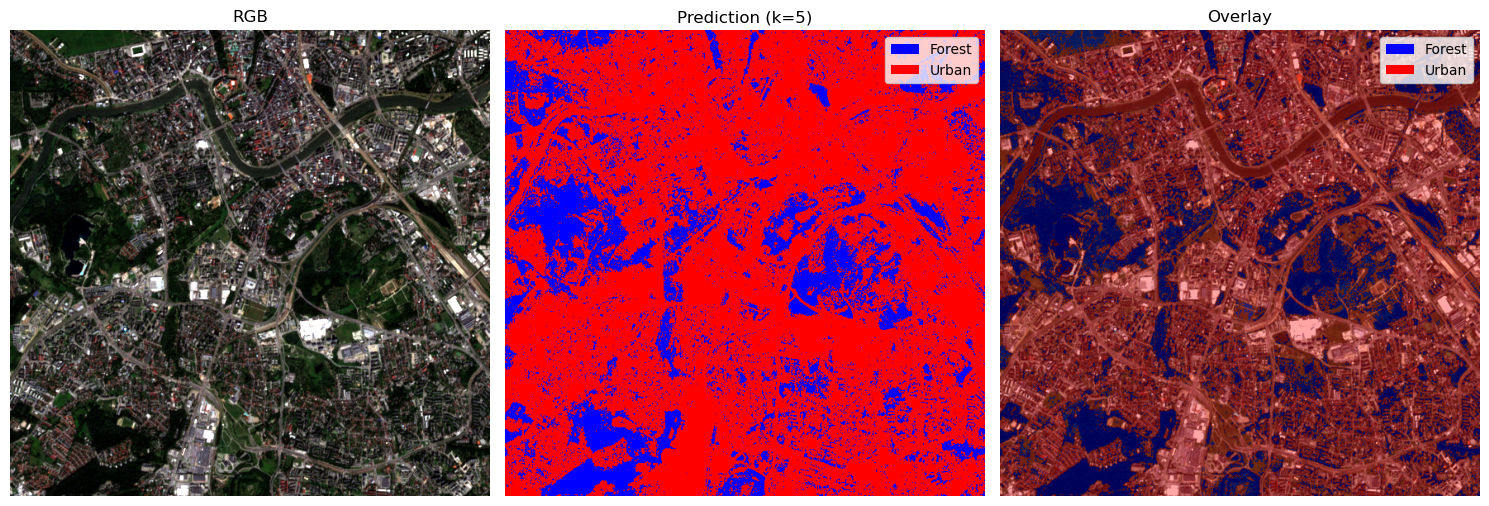

In [126]:
compare(s2_mixed, pred_1k_map, "k=1")
compare(s2_mixed, pred_3k_map, "k=3")
compare(s2_mixed, pred_5k_map, "k=5")

## *k* hyperparameter
From what I see, subtle difference is visible. When k parameter is higher, classifier tend to predict less single / alone pixels. It is like this because with higher k obviously more neighbors are being taken into account and that may produce steadier and more robust results especially with two different classes clusters next to each other. We can say that increasing k smooths the resulting prediction mask. Also what is worth mentioning, we are not treating pixel next to pixel as a neighbor, we basically created a 3 dimensional space and we are comparing closest RGB vectors, not pixels nearby the currently analysed pixel.

In [127]:
print(np.sum(pred_1k_map))
print(np.sum(pred_3k_map))
print(np.sum(pred_5k_map))

256124
258721
259359
